# NEXORA CARE FLOW
## Appointment Records – Feature Engineering

### Project Overview
This feature engineering stage prepares the Nexora Care Flow appointment records for time-series forecasting by transforming the cleaned data into a structured clinic-level dataset.

The analysis aggregates appointment records into daily clinic volumes and creates features that capture calendar patterns, holiday and seasonal effects, previous appointment demand, and recent demand trends. These features will provide the foundation for developing a forecasting model to predict future appointment volumes.

### Feature Engineering Objectives
# We are creating the following feature engineering for our analysis

1. appointment_volume — our forecasting target
2. is_holiday — whether the day is a holiday
3. day_of_week — captures weekly patterns

In [1]:
# Load libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
# Load the cleaned eda dataset
df = pd.read_csv(r'C:\Users\telvi\Downloads\AMDARI\Nexora_Care_Flow\data\processed_data\AppointmentRecords_eda.csv'
)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129353 entries, 0 to 129352
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   AppointmentID         129353 non-null  int64 
 1   ClinicID              129353 non-null  int64 
 2   ClinicName            129353 non-null  object
 3   ClinicType            129353 non-null  object
 4   PatientID             129353 non-null  int64 
 5   ProviderID            129353 non-null  int64 
 6   AppointmentDateTime   129353 non-null  object
 7   AppointmentType       129353 non-null  object
 8   Status                129353 non-null  object
 9   BookingChannel        129353 non-null  object
 10  BookingLeadTimeDays   129353 non-null  int64 
 11  IsHoliday             129353 non-null  bool  
 12  HolidayName           129353 non-null  object
 13  SeasonFlag            129353 non-null  object
 14  ChronicConditionFlag  129353 non-null  bool  
 15  DayOfWeek        

In [4]:
# CSV files do not preserve pandas datetime types, convert AppointmentDateTime again:
df['AppointmentDateTime'] = pd.to_datetime(
    df['AppointmentDateTime']
)

# We need the date in datetime format so we can group appointments by day and extract the day of the week.

In [5]:
# confirm if the AppointmentDateTime has change to datetime
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129353 entries, 0 to 129352
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   AppointmentID         129353 non-null  int64         
 1   ClinicID              129353 non-null  int64         
 2   ClinicName            129353 non-null  object        
 3   ClinicType            129353 non-null  object        
 4   PatientID             129353 non-null  int64         
 5   ProviderID            129353 non-null  int64         
 6   AppointmentDateTime   129353 non-null  datetime64[ns]
 7   AppointmentType       129353 non-null  object        
 8   Status                129353 non-null  object        
 9   BookingChannel        129353 non-null  object        
 10  BookingLeadTimeDays   129353 non-null  int64         
 11  IsHoliday             129353 non-null  bool          
 12  HolidayName           129353 non-null  object        
 13 

# appointment_volume

In [6]:
# Create daily appointment volume
# Count the number of appointments for each day
# .dt.date removes the time component and keeps only the date.
daily = (
    df.groupby(
        df["AppointmentDateTime"].dt.date
    )
    .size()
    .reset_index(
        name="appointment_volume"
    )
)
# Convert the date column back to datetime format
daily["AppointmentDateTime"] = pd.to_datetime(
    daily["AppointmentDateTime"]
)

# Sort the data chronologically
daily = daily.sort_values(
    "AppointmentDateTime"
)

# Display the first few rows
daily.head()


,AppointmentDateTime,appointment_volume
0,2024-01-01,31
1,2024-01-02,221
2,2024-01-03,167
3,2024-01-04,171
4,2024-01-05,103


# Instead of having individual appointment records eg (Patient 1 → 01/01/2025), we now have
# (AppointmentDateTime    appointment_volume 2025-01-01             3), this is important because 
# appointment_volume is the thing we eventually want to forecast.


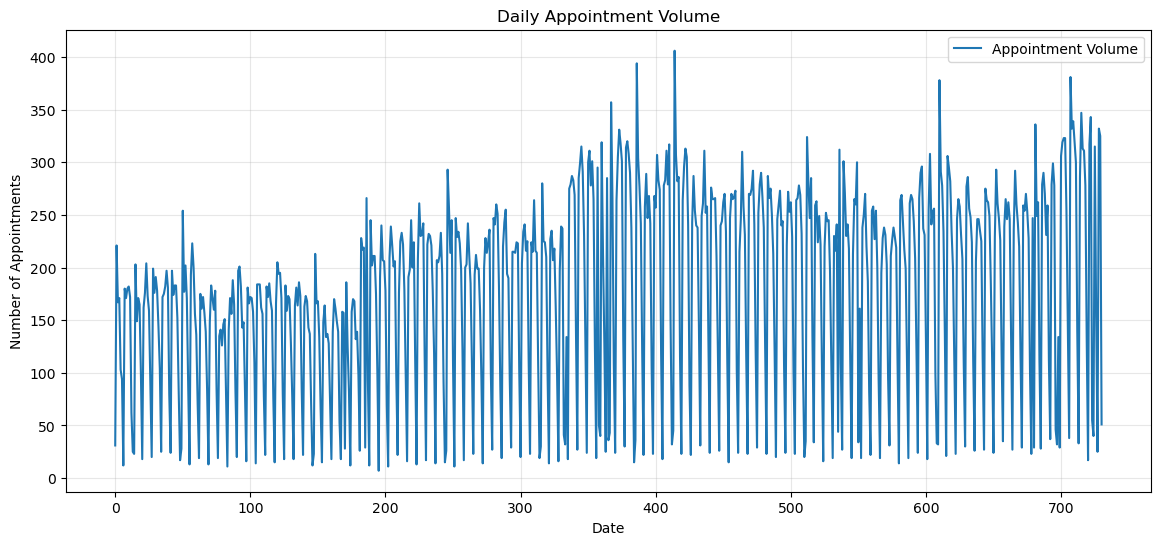

In [7]:
# Daily appointment volume — Line plot
# Shows the overall trend and seasonality over time.
plt.figure(figsize=(14, 6))

plt.plot(
    daily.index,
    daily["appointment_volume"],
    label="Appointment Volume"
)

plt.title("Daily Appointment Volume")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
# Create a continuous daily index
# Set AppointmentDateTime as the index
daily = daily.set_index(
    "AppointmentDateTime"
)

# Ensure that every calendar day is represented
# Missing days are given an appointment volume of 0.
daily = daily.asfreq(
    "D",
    fill_value=0
)

# Display the result
daily.head()

,appointment_volume
AppointmentDateTime,
2024-01-01,31
2024-01-02,221
2024-01-03,167
2024-01-04,171
2024-01-05,103


# Create is_holiday

In [9]:
# Your original dataset already contains: IsHoliday and HolidayName
# Create one IsHoliday value for each day.
# .max() means that if any appointment on a day
# is marked as a holiday, that day is treated as a holiday.
holiday_daily = (
    df.groupby(
        df["AppointmentDateTime"].dt.date
    )["IsHoliday"]
    .max()
)

# Convert the index to datetime
# so that it matches the daily dataframe.
holiday_daily.index = pd.to_datetime(
    holiday_daily.index
)

# Add the holiday indicator to the daily dataframe.
# 1 = Holiday
# 0 = Not a holiday
daily["is_holiday"] = (
    holiday_daily
    .reindex(
        daily.index,
        fill_value=0
    )
    .astype(int)
)

is_holiday important bcos Appointment demand may be different on holidays.
For example:
Normal Monday       → 100 appointments
Holiday Monday      → 60 appointments
This feature gives models such as SARIMAX, Prophet and XGBoost information about that potential change.

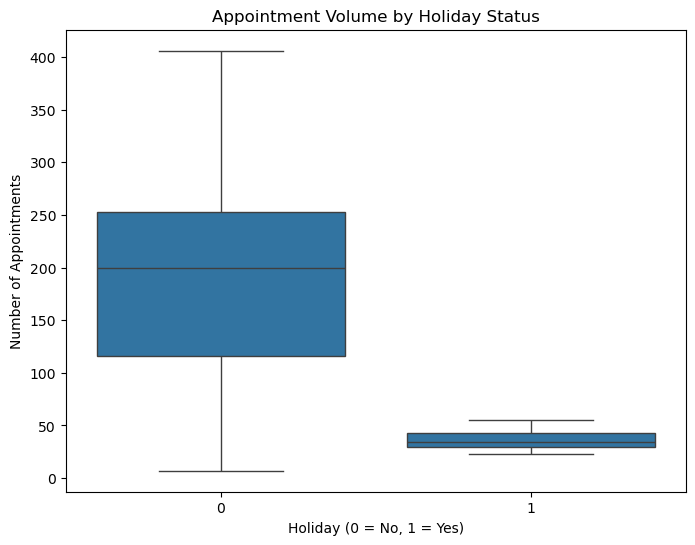

In [10]:
# Shows whether appointment volume differs between holidays and non-holidays.
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=daily,
    x="is_holiday",
    y="appointment_volume"
)

plt.title("Appointment Volume by Holiday Status")
plt.xlabel("Holiday (0 = No, 1 = Yes)")
plt.ylabel("Number of Appointments")
plt.show()

In [11]:
# Check the index type
print(type(daily.index))

# Check the columns
print(daily.columns)

# Display the first few rows
daily.head()

<class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Index(['appointment_volume', 'is_holiday'], dtype='object')


,appointment_volume,is_holiday
AppointmentDateTime,,
2024-01-01,31,1
2024-01-02,221,0
2024-01-03,167,0
2024-01-04,171,0
2024-01-05,103,0


#  Create day_of_week

In [12]:
# Extract the day of the week from the date. Monday = 0, Tuesday = 1,...... Sunday = 6
daily["day_of_week"] = daily.index.dayofweek

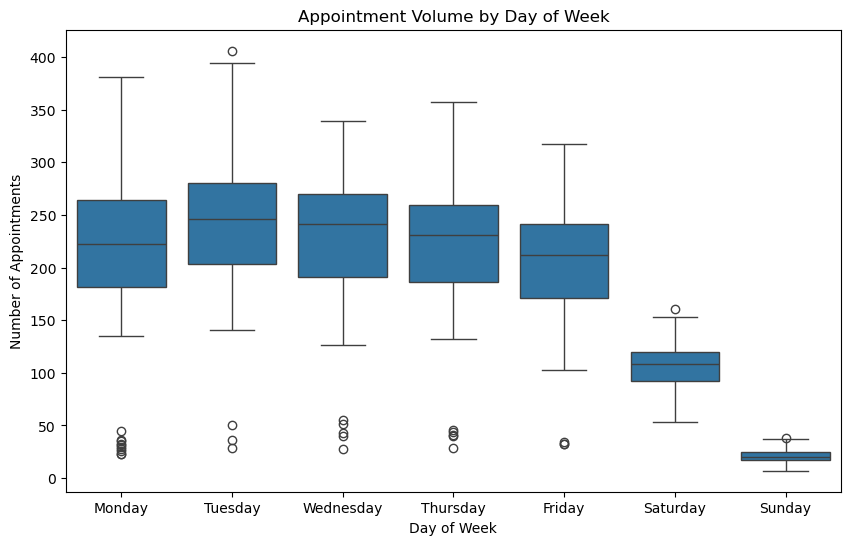

In [13]:
# Weekly pattern — Box plot
# Shows how appointment volume varies across Monday–Sunday.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=daily,
    x="day_of_week",
    y="appointment_volume"
)

plt.title("Appointment Volume by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Appointments")

plt.xticks(
    range(7),
    ["Monday", "Tuesday", "Wednesday", "Thursday",
     "Friday", "Saturday", "Sunday"]
)

plt.show()

# day_of_week is important cos Healthcare appointment demand may follow a weekly pattern.
# For instance Monday       → High, Tuesday      → High, and Wednesday    → Medium

In [14]:
# Display the engineered features
daily[
    [
        "appointment_volume",
        "is_holiday",
        "day_of_week"
    ]
].head(10)

,appointment_volume,is_holiday,day_of_week
AppointmentDateTime,,,
2024-01-01,31,1,0
2024-01-02,221,0,1
2024-01-03,167,0,2
2024-01-04,171,0,3
2024-01-05,103,0,4
2024-01-06,94,0,5
2024-01-07,12,0,6
2024-01-08,180,0,0
2024-01-09,171,0,1


In [15]:
# Check the shape of the engineered dataset
print(daily.shape)

# Check the columns
print(daily.columns.tolist())

# Check for missing values
print(daily.isna().sum())

# Display the final dataset
daily.head()

(731, 3)
['appointment_volume', 'is_holiday', 'day_of_week']
appointment_volume    0
is_holiday            0
day_of_week           0
dtype: int64


,appointment_volume,is_holiday,day_of_week
AppointmentDateTime,,,
2024-01-01,31,1,0
2024-01-02,221,0,1
2024-01-03,167,0,2
2024-01-04,171,0,3
2024-01-05,103,0,4


Variable	                Role	            Purpose
appointment_volume	        Target	            Number of appointments to forecast
is_holiday	Feature	        Captures            holiday-related demand changes
day_of_week	Feature	        Captures             weekly appointment patterns.
appointment_volume is our target variable to use in our forcasting model.

In [16]:
# save to my processed_data folder
daily.to_csv(
    r'C:\Users\telvi\Downloads\AMDARI\Nexora_Care_Flow\data\processed_data\AppointmentRecords_feature_eng.csv',
    index=True
)